# Valuing a gas storage contract: a walkthrough

This notebook goes through the project from the beginning: the contract, the price model, and the
three ways of valuing the storage that we compare (intrinsic and rolling intrinsic, Least-Squares
Monte Carlo, and a neural network policy). The heavy lifting lives in `src/`; here we call those
functions, look at the numbers and explain what is going on.

A gas storage contract gives you the right to inject gas into a reservoir, keep it, and withdraw it
later. The natural trade is to buy cheap gas in summer and sell it in winter, but the real value is
in the flexibility: if prices move, you can change your plan. Valuing the contract means valuing
that flexibility, under physical limits (capacity, and injection and withdrawal rates that depend on
how full the storage is).

A few conventions used everywhere:

* prices in EUR/MWh (TTF style), volumes in MWh, time in years (ACT/365);
* the storage year runs from 1 April 2027 to 31 March 2028, with one decision per day (366 days);
* every Monte Carlo number comes with a 95% confidence interval;
* the policies from LSMC and the neural network are always valued on fresh paths that were not used
  to build them (out-of-sample).

The full-size runs (20,000 paths everywhere) are in `scripts/`. Some cells here use fewer paths so
that the notebook runs in a few minutes; the numbers from the full runs are quoted where relevant.

In [1]:
import os
import sys

# The notebook lives in notebooks/, the code in src/: add the repository root to the path.
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt

from src.config_loader import load_config
from src.scenario import build_scenario, simulate_paths
from src.evaluation import (mean_confidence_interval, control_variate_confidence_interval,
                            difference_confidence_interval)

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e4e3df"

config = load_config()
scenario = build_scenario(config)
contract = scenario["contract"]

In [2]:
def show_ci(label, ci):
    # Print a Monte Carlo estimate with its 95% confidence interval.
    print("{:38s} {:>13,.0f}   95% CI [{:,.0f}, {:,.0f}]".format(label, ci["mean"], ci["low"], ci["high"]))

## 1. The contract

All parameters sit in `config/config.toml`. The storage holds 1 TWh of working gas (WGV). It starts
empty on 1 April and must be empty again at the end of March. At full speed, filling the storage
takes 150 days and emptying it takes 90 days.

The speeds are not constant. Like real storage sites, the contract has *ratchets*:

* injection runs at full speed up to 70% full, then slows down linearly to half speed when full
  (pressure builds up in the reservoir);
* withdrawal runs at full speed down to 30% full, then slows down to 40% of full speed when empty.

The rate on a given day depends on the inventory at the start of that day. Injecting costs
0.20 EUR/MWh, withdrawing 0.10 EUR/MWh, and cash flows are discounted at 3%.

Working volume         : 1,000,000 MWh
Max injection rate     : 6,667 MWh/day
Max withdrawal rate    : 11,111 MWh/day
Days to fill (empty -> full) : 168
Days to empty (full -> empty): 104


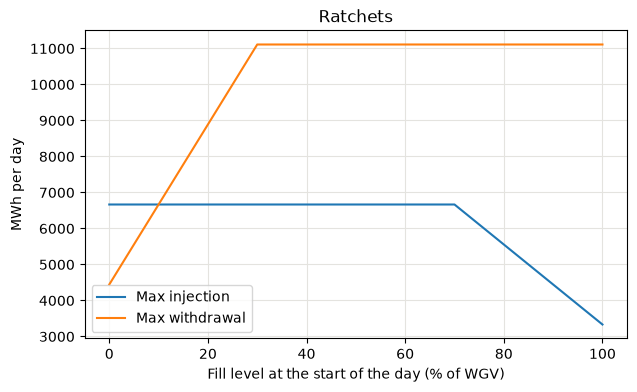

In [3]:
from src.contract import max_injection, max_withdrawal, days_to_fill, days_to_empty

print("Working volume         : {:,.0f} MWh".format(contract.working_volume))
print("Max injection rate     : {:,.0f} MWh/day".format(contract.max_injection_rate))
print("Max withdrawal rate    : {:,.0f} MWh/day".format(contract.max_withdrawal_rate))
print("Days to fill (empty -> full) :", days_to_fill(contract))
print("Days to empty (full -> empty):", days_to_empty(contract))

fill = np.linspace(0.0, 1.0, 201)
inventory = fill * contract.working_volume
plt.figure(figsize=(7, 4))
plt.plot(100 * fill, max_injection(contract, inventory), label="Max injection")
plt.plot(100 * fill, max_withdrawal(contract, inventory), label="Max withdrawal")
plt.xlabel("Fill level at the start of the day (% of WGV)")
plt.ylabel("MWh per day")
plt.title("Ratchets")
plt.legend()
plt.show()

Because of the ratchets it takes 168 days to fill, not 150, and 104 days to empty, not 90. Summer
(April to September) has 183 days and winter has 182, so a full cycle fits, but not with much room.

One detail matters later: both ratchet curves are *concave* (they only bend downwards). A concave
piecewise-linear function is the minimum of its straight pieces, so a constraint like
"injection <= ratchet(inventory)" can be written as a few linear constraints. That is what keeps the
intrinsic problem a linear program.

## 2. The price model

We use the two-factor model of Schwartz and Smith (2000), with a deterministic seasonal term:

$$\ln S_t = f(t) + \chi_t + \xi_t$$

* $\chi_t$ is the short-term factor, an Ornstein-Uhlenbeck process pulled back to zero:
  $d\chi_t = -\kappa \chi_t\,dt + \sigma_\chi\,dW^1_t$. It captures weather shocks and other
  temporary moves. With $\kappa = 4$ the half-life of a shock is about two months.
* $\xi_t$ is the long-term factor, a Brownian motion: $d\xi_t = \mu_\xi\,dt + \sigma_\xi\,dW^2_t$.
  It captures permanent changes in the price level.
* the two Brownian motions have correlation $\rho$.

Parameters (until we calibrate on real data): $\kappa = 4$, $\sigma_\chi = 0.70$, $\sigma_\xi = 0.25$,
$\rho = -0.2$. We work directly under the pricing measure, so futures are expectations of the spot.

**Fitting the forward curve.** Since $\ln S_T$ is Gaussian, $F(0,T) = E[S_T] = \exp(f(T) + E[X_T] + \tfrac12 \mathrm{Var}[X_T])$
with $X = \chi + \xi$. We simply choose

$$f(T) = \ln F_{\text{input}}(T) - E[X_T] - \tfrac12 \mathrm{Var}[X_T],$$

and the model reproduces the input curve exactly. The input curve is monthly and synthetic: summer
around 29-31 EUR/MWh, winter up to 39.5. Every day of a month gets that month's price.

**Futures at a later date.** The same Gaussian argument gives the futures curve seen at time $t$:

$$F(t,T) = \exp\big(f(T) + e^{-\kappa(T-t)}\chi_t + \xi_t + \mu_\xi (T-t) + \tfrac12 V(T-t)\big).$$

Note how $\chi_t$ is damped by $e^{-\kappa(T-t)}$ while $\xi_t$ moves the whole curve. This
difference will turn out to matter a lot.

**Simulation.** Over one day the pair $(\chi, \xi)$ has a Gaussian transition with known mean and
covariance, so we sample it exactly (Cholesky of a 2x2 matrix), with no discretisation error. All
paths are simulated at once in NumPy arrays.

Simulated spot prices: (20000, 366) (paths x days)


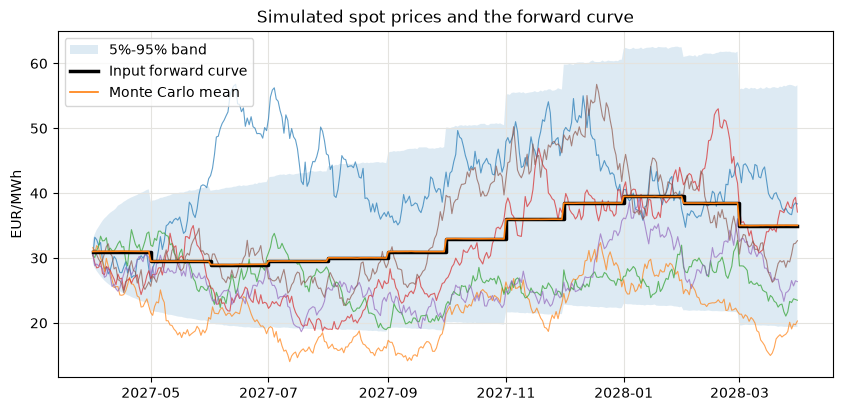

In [4]:
from src.forward_curve import monthly_averages

dates = scenario["dates"]
paths = simulate_paths(scenario, 20000, seed=config["simulation"]["seed"])
spot = paths["spot"]
print("Simulated spot prices:", spot.shape, "(paths x days)")

plt.fill_between(dates, np.quantile(spot, 0.05, axis=0), np.quantile(spot, 0.95, axis=0),
                 alpha=0.15, label="5%-95% band")
for i in range(6):
    plt.plot(dates, spot[i], linewidth=0.8, alpha=0.7)
plt.step(dates, scenario["daily_forward"], where="post", color="black", linewidth=2.5,
         label="Input forward curve")
plt.plot(dates, spot.mean(axis=0), color="tab:orange", linewidth=1.2, label="Monte Carlo mean")
plt.ylabel("EUR/MWh")
plt.title("Simulated spot prices and the forward curve")
plt.legend(loc="upper left")
plt.show()

**Check 1: does the simulation reproduce the forward curve?** For each month we average the spot
price over the days of the month, path by path. Its expectation should be exactly the monthly
forward.

In [5]:
monthly_spot = monthly_averages(spot, scenario["month_index"], len(scenario["months"]))

print("{:8s} {:>8s} {:>9s}   {:>20s}".format("month", "forward", "MC mean", "95% CI"))
for m in range(len(scenario["months"])):
    ci = mean_confidence_interval(monthly_spot[:, m])
    print("{:8s} {:8.2f} {:9.3f}   [{:7.3f}, {:7.3f}]".format(
        scenario["month_labels"][m], scenario["monthly_prices"][m], ci["mean"], ci["low"], ci["high"]))

month     forward   MC mean                 95% CI
2027-04     31.00    31.033   [ 30.987,  31.078]
2027-05     29.50    29.521   [ 29.447,  29.595]
2027-06     29.00    29.006   [ 28.919,  29.094]
2027-07     29.50    29.534   [ 29.437,  29.631]
2027-08     30.00    30.025   [ 29.920,  30.130]
2027-09     31.00    30.998   [ 30.884,  31.112]
2027-10     33.00    32.969   [ 32.843,  33.095]
2027-11     36.00    35.972   [ 35.830,  36.114]
2027-12     38.50    38.465   [ 38.309,  38.622]
2028-01     39.50    39.482   [ 39.316,  39.648]
2028-02     38.50    38.470   [ 38.304,  38.636]
2028-03     35.00    35.024   [ 34.869,  35.179]


All twelve forwards fall inside their confidence intervals, and the errors are around 0.1%.

**Check 2: the variance of log prices.** The empirical variance of $\ln S_t$ across paths should
match the closed form $V(t)$.

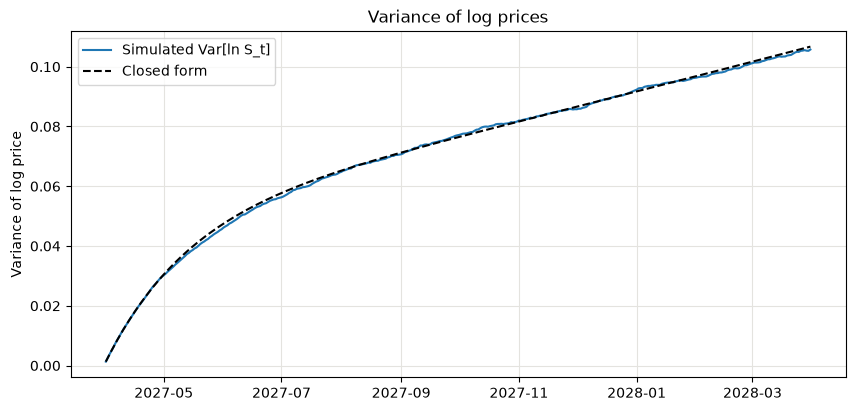

In [6]:
from src.model import variance_log_factors

log_spot = np.log(spot)
plt.plot(dates, log_spot.var(axis=0), label="Simulated Var[ln S_t]")
plt.plot(dates, variance_log_factors(scenario["params"], scenario["times"]), "k--",
         label="Closed form")
plt.ylabel("Variance of log price")
plt.title("Variance of log prices")
plt.legend()
plt.show()

The curves sit on top of each other. The variance rises fast during the first two months (the
short-term factor builds up) and then grows linearly (the long-term factor). With one seed, some days
fall slightly outside their confidence interval, which is expected since consecutive days are very
correlated; with a million paths every factor variance and covariance matches the formula to
about 0.3%. The unit tests in `tests/test_model.py` also check that one big step and 365 daily steps
give the same distribution, which confirms the simulation is exact.

## 3. Intrinsic value

The intrinsic value is what you get if you decide the whole schedule today, using today's forward
curve, and never change it. You can lock it in by buying the summer forwards and selling the winter
forwards, so it is a guaranteed lower bound on the storage value.

With injection $i_d$, withdrawal $w_d$ and inventory $V_d$, it is a linear program:

$$\max \sum_d DF_d\left[(F_d - c_{wd})\,w_d - (F_d + c_{inj})\,i_d\right]$$

subject to $V_{d+1} = V_d + i_d - w_d$, $0 \le V_d \le WGV$, $V_0 = V_{366} = 0$, and the ratchet
constraints written as straight pieces: $i_d \le a_k + b_k V_d$ for each piece $k$. We solve it with
`scipy.optimize.linprog` (HiGHS). It has about 1,100 variables and solves in a few hundredths of a
second.

In [7]:
from src.intrinsic import solve_intrinsic, schedule_violations, intrinsic_value_dp

intrinsic = solve_intrinsic(contract, scenario["daily_forward"], scenario["discount"])
intrinsic_value = intrinsic["value"]
print("Intrinsic value: {:,.0f} EUR  ({:.2f} EUR per MWh of capacity)".format(
    intrinsic_value, intrinsic_value / contract.working_volume))
print("Largest constraint violation (MWh): {:.1e}".format(max(schedule_violations(contract, intrinsic["net_volume"]).values())))

Intrinsic value: 7,826,175 EUR  (7.83 EUR per MWh of capacity)
Largest constraint violation (MWh): 1.2e-08


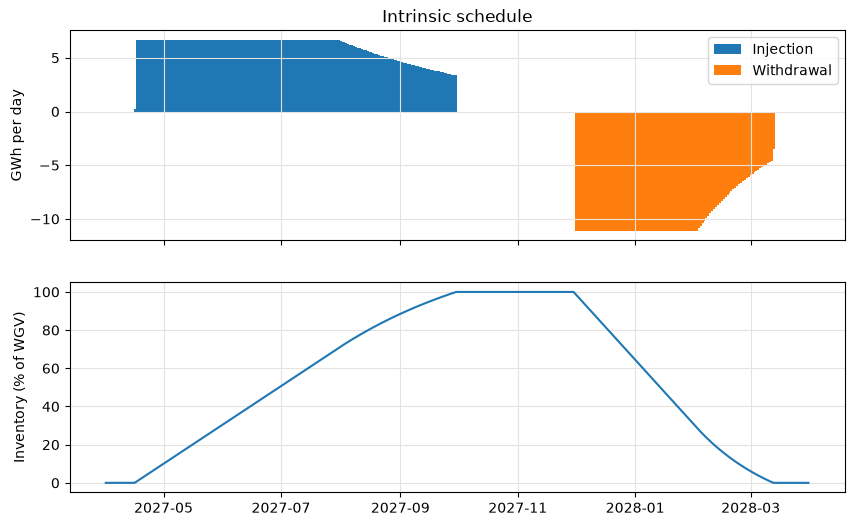

Net volume per month (the forward hedge):
  2027-04      93,575 MWh
  2027-05     206,667 MWh
  2027-06     200,000 MWh
  2027-07     206,664 MWh
  2027-08     173,629 MWh
  2027-09     119,466 MWh
  2027-10           0 MWh
  2027-11           0 MWh
  2027-12    -344,444 MWh
  2028-01    -344,444 MWh
  2028-02    -244,613 MWh
  2028-03     -66,498 MWh


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].bar(dates, intrinsic["injection"] / 1000, width=1.0, label="Injection")
axes[0].bar(dates, -intrinsic["withdrawal"] / 1000, width=1.0, label="Withdrawal")
axes[0].set_ylabel("GWh per day")
axes[0].legend()
axes[1].plot(dates, 100 * intrinsic["inventory"][1:] / contract.working_volume)
axes[1].set_ylabel("Inventory (% of WGV)")
axes[0].set_title("Intrinsic schedule")
plt.show()

print("Net volume per month (the forward hedge):")
for m in range(len(scenario["months"])):
    in_month = scenario["month_index"] == m
    print("  {}  {:>10,.0f} MWh".format(scenario["month_labels"][m], intrinsic["net_volume"][in_month].sum()))

The schedule looks like what a trader would do by hand: buy from mid-April to the end of September
(slowing down above 70% full because of the ratchet), wait through October and November, and sell
from December to mid-March (slowing down below 30%). April is skipped at first because it is more
expensive than May to August.

We never trust a solver blindly, so here are two independent checks.

* **Dynamic programming.** We solve the same deterministic problem by backward induction on an
  inventory grid. Grid schedules are a subset of LP schedules, so the DP value must be below the LP
  value and get closer as the grid gets finer.
* **Monte Carlo.** We apply the fixed schedule to the simulated spot paths. Since $E[S_d] = F(0,d)$
  and the schedule does not depend on the path, the mean cash flow must equal the LP value.

In [9]:
for step in [500.0, 100.0]:
    dp_value = intrinsic_value_dp(contract, scenario["daily_forward"], scenario["discount"], step)
    print("DP with a {:>4.0f} MWh grid: {:,.0f} EUR  (gap to LP {:.2f}%)".format(
        step, dp_value, 100 * (intrinsic_value - dp_value) / intrinsic_value))

from src.intrinsic import schedule_discounted_cash_flows

intrinsic_on_paths = schedule_discounted_cash_flows(contract, spot, intrinsic["net_volume"],
                                                    scenario["discount"]).sum(axis=1)
show_ci("Fixed schedule on 20,000 paths", mean_confidence_interval(intrinsic_on_paths))
print("Standard deviation per path: {:,.0f} EUR".format(intrinsic_on_paths.std()))

DP with a  500 MWh grid: 7,742,164 EUR  (gap to LP 1.07%)


DP with a  100 MWh grid: 7,806,400 EUR  (gap to LP 0.25%)
Fixed schedule on 20,000 paths             7,781,832   95% CI [7,641,936, 7,921,728]
Standard deviation per path: 10,093,940 EUR


Both checks pass. The standard deviation is a useful reminder: if you follow the schedule but do not
hedge it, you carry about 10 million EUR of price risk. The intrinsic value is risk-free only once the
forwards are traded.

The variable `intrinsic_on_paths` will be useful again: its expectation is known exactly (the LP
value), so we use it as a **control variate** for the other methods. It is strongly correlated with
any sensible storage strategy and makes the confidence intervals about 2.7 times narrower.

## 4. Least-Squares Monte Carlo

The intrinsic value ignores the fact that we can react to prices. To capture that, we solve the real
dynamic problem: each day, given the inventory and the current state of the market, inject, withdraw
or do nothing. We follow Boogert and de Jong (2008).

**Backward induction on simulated paths.** We put an inventory grid of 101 levels on each day and
start from the last day. For each day and each grid level:

1. The *continuation value* (the expected value of the future given today's market) is estimated by
   regressing the realised future values of all paths on a few functions of today's market state.
2. We compare the three actions (inject at full rate, do nothing, withdraw at full rate). After a
   trade the inventory usually lands between two grid levels, so we interpolate the continuation
   value linearly.
3. Each path takes its best action, and we update its realised value with the actual cash flows,
   in the Longstaff-Schwartz way.

**The terminal condition is hard.** We first compute, for each day, the range of inventories from
which the storage can still be emptied by the end of March given the withdrawal ratchet. Every action
keeps the inventory inside that range, so every path ends at exactly zero. The grid is placed on that
range day by day ("adaptive" grid).

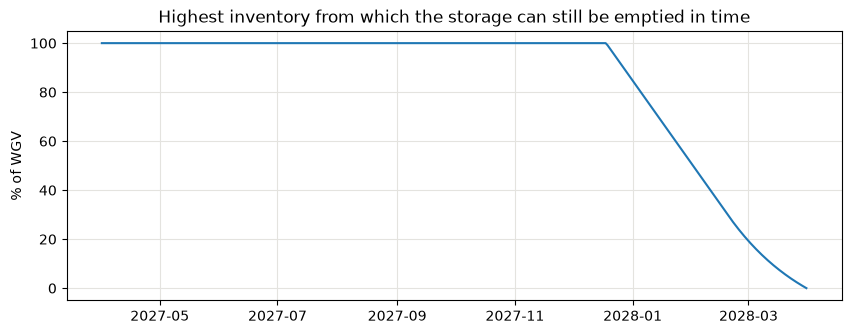

In [10]:
from src.lsmc import reachable_band

lower, upper = reachable_band(contract, len(dates))
plt.figure(figsize=(10, 3.5))
plt.plot(dates, 100 * upper[1:] / contract.working_volume)
plt.ylabel("% of WGV")
plt.title("Highest inventory from which the storage can still be emptied in time")
plt.show()

The curve stays at 100% until mid-December, then drops: from that point a full storage can no longer
be emptied by 31 March. It is exactly the 104-day emptying time we found in section 1.

**Out-of-sample valuation.** The regressions are fitted on 10,000 paths (one seed). The resulting
policy is then applied to the 20,000 valuation paths (another seed). The in-sample number is biased
upwards because the regression has seen the future of those very paths, so we only report it for
comparison.

**Which regression variables?** Our first choice was polynomials in the spot price:
$1, S, S^2, S^3$. We now regress on polynomials in the two factors $(\chi, \xi)$ up to degree 3.
Both are run below on the same paths.

In [11]:
import copy
from src.lsmc import lsmc_backward, lsmc_forward

regression_paths = simulate_paths(scenario, 10000, seed=config["lsmc"]["seed_regression"])
valuation_paths = simulate_paths(scenario, 20000, seed=config["valuation"]["seed"])
valuation_spot = valuation_paths["spot"]

# The control variate on the valuation paths (its mean is exactly the intrinsic value).
control = schedule_discounted_cash_flows(contract, valuation_spot, intrinsic["net_volume"],
                                         scenario["discount"]).sum(axis=1)

lsmc_values = {}
for basis in ["spot", "factors"]:
    settings = copy.deepcopy(config["lsmc"])
    settings["basis"] = basis
    policy, in_sample = lsmc_backward(contract, regression_paths["spot"], scenario["discount"],
                                      settings, factors=regression_paths)
    values, volumes, _ = lsmc_forward(contract, valuation_spot, scenario["discount"], policy,
                                      factors=valuation_paths)
    lsmc_values[basis] = values
    print("Basis:", basis)
    show_ci("  in-sample (biased up)", mean_confidence_interval(in_sample))
    show_ci("  out-of-sample", mean_confidence_interval(values))
    show_ci("  out-of-sample, control variate", control_variate_confidence_interval(values, control, intrinsic_value))
    print("  largest constraint violation (MWh): {:.1e}".format(max(schedule_violations(contract, volumes).values())))

lsmc_volumes = volumes   # the factor basis ran last
show_ci("Factor basis - spot basis (paired)", difference_confidence_interval(lsmc_values["factors"], lsmc_values["spot"]))

Basis: spot
  in-sample (biased up)                    9,264,186   95% CI [9,093,729, 9,434,644]
  out-of-sample                            9,125,306   95% CI [9,003,861, 9,246,750]
  out-of-sample, control variate           9,196,960   95% CI [9,153,133, 9,240,788]
  largest constraint violation (MWh): 2.7e-11


Basis: factors
  in-sample (biased up)                   10,083,384   95% CI [9,912,133, 10,254,635]
  out-of-sample                            9,916,565   95% CI [9,795,729, 10,037,401]
  out-of-sample, control variate           9,987,588   95% CI [9,942,886, 10,032,291]
  largest constraint violation (MWh): 2.7e-11
Factor basis - spot basis (paired)           791,259   95% CI [752,309, 830,209]


The factor basis is worth about 790,000 EUR more, on exactly the same paths. Here is why. The spot
price only tells us $\chi + \xi$. Suppose the price is high in July. If it is high because of
$\chi$ (a heat wave), the move will fade within weeks: better to wait and inject later. If it is
high because of $\xi$, the whole curve has moved up, winter included, and the summer-winter spread is
unchanged. The two situations call for different decisions, and only a regression on both factors
can tell them apart.

We found this by accident. Rolling intrinsic (next section) first came out *above* the spot-basis
LSMC, which should not happen. Rolling intrinsic sees the whole forward curve, and so both factors;
that is what pointed to the regression basis.

A few other things we checked on the full runs (paired differences on the same paths):

* a fixed grid on [0, WGV] with a terminal penalty, instead of the adaptive grid, loses about 180,000
  EUR: near maturity, interpolation mixes feasible inventories with penalised ones;
* 51 or 201 grid levels, polynomial degree 4, 20,000 regression paths, or allowing partial volumes
  all change the value by less than about 3,000 EUR, so these choices have converged.

**An upper bound.** If we knew the whole price path in advance, we could solve the LP on each path.
No real strategy can beat that, so its mean is an upper bound. It is a loose bound with this much
short-term volatility, but it is a useful sanity check.

In [12]:
n_foresight = 200
foresight = np.empty(n_foresight)
for i in range(n_foresight):
    foresight[i] = solve_intrinsic(contract, valuation_spot[i], scenario["discount"])["value"]

show_ci("Perfect foresight (200 paths)", mean_confidence_interval(foresight))
show_ci("Perfect foresight - LSMC (paired)",
        difference_confidence_interval(foresight, lsmc_values["factors"][:n_foresight]))

Perfect foresight (200 paths)             14,647,988   95% CI [13,579,006, 15,716,970]
Perfect foresight - LSMC (paired)          4,587,579   95% CI [4,187,508, 4,987,650]


## 5. Rolling intrinsic

Rolling intrinsic is what many desks actually do. Every week, take the current forward curve,
re-solve the intrinsic LP from the current inventory, trade the difference in forwards, and follow
the new plan until the next week. Each new plan can always keep the old one, so rolling intrinsic is
worth at least the intrinsic value.

In the model, the forward curve on day $d$ comes from the formula of section 2, using the simulated
$\chi_d$ and $\xi_d$ of each path. On day $d$ itself the "forward" is the spot price. The forward
trades along the way have zero expected profit under the pricing measure, so the expected value of
the strategy is just the expected discounted cash flow of the gas actually moved.

One run needs one LP per path and per week. The full run (20,000 paths, 1.06 million LPs) takes
about 30 minutes on 8 cores, so here we use the first 400 valuation paths.

In [13]:
from src.rolling_intrinsic import run_rolling_intrinsic

n_rolling = 400
rolling_volumes = run_rolling_intrinsic(scenario, valuation_paths["chi"][:n_rolling],
                                        valuation_paths["xi"][:n_rolling], 7, n_workers=8)
rolling_values = schedule_discounted_cash_flows(contract, valuation_spot[:n_rolling], rolling_volumes,
                                                scenario["discount"]).sum(axis=1)

show_ci("Rolling intrinsic, weekly (400 paths)",
        control_variate_confidence_interval(rolling_values, control[:n_rolling], intrinsic_value))
show_ci("LSMC - rolling intrinsic (paired)",
        difference_confidence_interval(lsmc_values["factors"][:n_rolling], rolling_values))

Rolling intrinsic, weekly (400 paths)      9,756,550   95% CI [9,419,421, 10,093,678]
LSMC - rolling intrinsic (paired)            305,693   95% CI [184,723, 426,662]


With only 400 paths the intervals are wide. On the full 20,000 paths, weekly rolling intrinsic is
worth 9.68M EUR, which is 302,000 EUR below LSMC (95% CI [286k, 319k]). Re-optimising every day
instead of every week adds about 160,000 EUR, still below LSMC. Rolling intrinsic captures 86% of the
LSMC extrinsic value. That is impressive for such a simple rule, but it never chooses to *wait* for a
better price, and that is where the gap comes from.

## 6. A neural network policy

The last method is close to deep hedging. Instead of estimating continuation values, we directly
learn a policy: a small network that looks at the current state and decides how much to trade.

* **Inputs:** time left, fill level, position of the inventory inside the feasible range of section 4,
  and the standardised factors $\chi_d$ and $\xi_d$. These are the same state variables the LSMC
  regression uses.
* **Output:** a number $a \in [0, 1]$ (sigmoid). The trade is $q = q_{lo} + a\,(q_{hi} - q_{lo})$,
  where $[q_{lo}, q_{hi}]$ is the range of trades allowed today by the ratchets, the capacity and the
  need to be empty at the end. So the network cannot break a constraint, whatever its weights, and
  no penalty term is needed.
* **Training:** we simulate 2,048 fresh paths, run the policy through the 366 days, compute the mean
  discounted cash flow and take a gradient step with Adam. The cash flows are differentiable in the
  trades, so backpropagation goes through the whole year. A separate set of 5,000 validation paths
  is used only to keep the best weights.

Training takes about 40 minutes on a laptop CPU (10,000 iterations). Set `TRAIN_NETWORK = True` to
retrain. Otherwise the cell loads the weights saved by `scripts/run_step5_nn_policy.py`.

In [14]:
import torch
from src.nn_policy import PolicyNetwork, N_FEATURES, train_policy, evaluate_policy

TRAIN_NETWORK = False

nn_settings = config["nn_policy"]
if TRAIN_NETWORK:
    validation_paths = simulate_paths(scenario, nn_settings["n_paths_validation"], seed=nn_settings["seed_validation"])
    network, history = train_policy(scenario, nn_settings, validation_paths)

    iterations = []
    validation_values = []
    for row in history:
        iterations.append(row["iteration"])
        validation_values.append(row["validation_value"] / 1e6)
    plt.plot(iterations, validation_values)
    plt.xlabel("Iteration")
    plt.ylabel("Validation value (million EUR)")
    plt.title("Training curve")
    plt.show()
else:
    network = PolicyNetwork(N_FEATURES, nn_settings["hidden_sizes"])
    network.load_state_dict(torch.load(os.path.join("..", "results", "models", "nn_policy.pt")))
    print("Loaded the trained network from results/models/nn_policy.pt")

Loaded the trained network from results/models/nn_policy.pt


In [15]:
nn_values, nn_volumes = evaluate_policy(network, scenario, valuation_paths)

show_ci("Neural network policy", control_variate_confidence_interval(nn_values, control, intrinsic_value))
show_ci("Neural network - LSMC (paired)", difference_confidence_interval(nn_values, lsmc_values["factors"]))
print("Largest constraint violation (MWh): {:.1e}".format(max(schedule_violations(contract, nn_volumes).values())))

Neural network policy                      9,886,893   95% CI [9,841,590, 9,932,195]
Neural network - LSMC (paired)              -101,107   95% CI [-108,068, -94,146]
Largest constraint violation (MWh): 2.2e-11


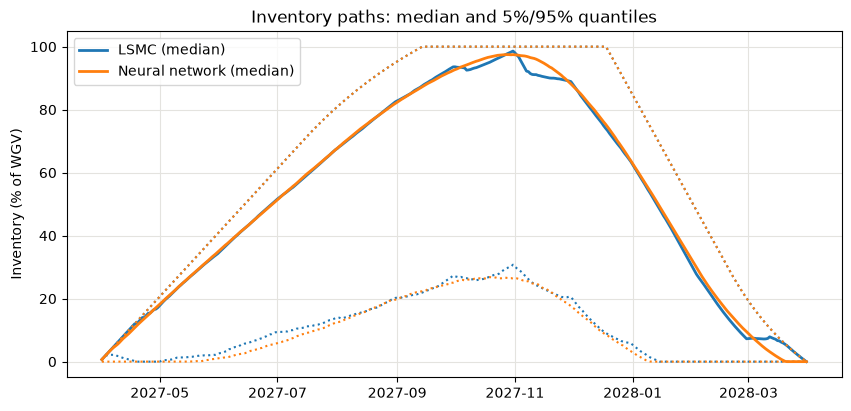

In [16]:
for name, volumes in [("LSMC", lsmc_volumes), ("Neural network", nn_volumes)]:
    fill = 100 * np.cumsum(volumes, axis=1) / contract.working_volume
    line = plt.plot(dates, np.median(fill, axis=0), linewidth=2, label=name + " (median)")
    colour = line[0].get_color()
    plt.plot(dates, np.quantile(fill, 0.05, axis=0), ":", color=colour)
    plt.plot(dates, np.quantile(fill, 0.95, axis=0), ":", color=colour)
plt.ylabel("Inventory (% of WGV)")
plt.title("Inventory paths: median and 5%/95% quantiles")
plt.legend()
plt.show()

The network reaches 9.89M EUR, about 100,000 EUR (1%) below LSMC, and captures 95% of the LSMC
extrinsic value. Its inventory distribution almost overlaps the LSMC one.

The training length mattered. A first run with 3,000 iterations stopped at 9.74M while it was still
improving; 10,000 iterations added about 140,000 EUR. The remaining gap is probably structural. The
best policy is bang-bang (full speed or nothing), which is a step function of the state. A sigmoid
trained by gradient only "sees" the step through its smooth part, so it learns where to put the
boundary slowly.

## 7. Where we stand

Results of the full runs, all on the same 20,000 valuation paths:

| Method | Value (EUR) | 95% CI |
|---|---|---|
| Intrinsic (LP) | 7,826,175 | exact |
| Rolling intrinsic, weekly | 9,684,960 | [9,638,830, 9,731,090] |
| Neural network policy | 9,886,893 | [9,841,590, 9,932,195] |
| LSMC (factor basis) | 9,987,588 | [9,942,886, 10,032,291] |
| Perfect foresight (upper bound, 1,000 paths) | 14,860,254 | [14,319,207, 15,401,300] |

So the ranking is intrinsic < rolling intrinsic < neural network < LSMC < perfect foresight. The
flexibility of the storage (extrinsic value) is worth about 2.2M EUR on top of the 7.8M of intrinsic
value, roughly 28%.

What we learned along the way:

* the intrinsic value is easy to compute exactly, and it is a good anchor: it gives an exact
  benchmark, a control variate and a check for every other method;
* the regression basis matters far more than the usual LSMC settings (grid size, number of paths,
  polynomial degree). The spot price alone throws away the information that separates temporary from
  permanent moves;
* how constraints are handled matters too. The hard terminal constraint through a feasible range
  works much better than a penalty;
* a neural policy gets close to LSMC without any regression design, but it needs a long training run.

Next steps: sensitivity analysis (volatilities, mean reversion, correlation, rates, volume and speed of
the storage), then real data: calibration on TTF or Henry Hub prices, storage parameters from GIE
AGSI+, and a backtest over the storage years 2015 to 2025.